# 5. Análisis estadístico (paso 7) y análisis exploratorio (paso 8)

Este notebook parte de las tablas del notebook 04 (`resultados/`) y responde dos preguntas:

- **Paso 7:** ¿las diferencias nativo vs no nativo que vimos son **reales** o pueden explicarse por azar? ¿Cambian según el electrodo?
- **Paso 8:** ¿la **familiaridad con el idioma** se relaciona con esas diferencias? ¿Qué **limitaciones** tiene el estudio?

Cada sección explica primero **qué se hace y por qué**, después muestra el resultado y al final dice **cómo leerlo**.

## 7.0 Conceptos básicos de estadística que usamos acá

**Test estadístico** Partimos de la **hipótesis nula (H₀)**: *la canción nativa y la no nativa producen la misma potencia, y cualquier diferencia que vemos es ruido.* El test calcula qué tan raro sería observar diferencias como las nuestras **si H₀ fuera cierta**.

**p-valor.** Es esa probabilidad. Por ejemplo, p = 0,04 quiere decir: *"si no hubiera ningún efecto real, vería diferencias así de grandes (o más) en el 4 % de los experimentos, solo por azar"*. Por convención, si p < 0,05 se dice que el resultado es **"estadísticamente significativo"**.

**Test pareado.** Cada sujeto escuchó **las dos** canciones, así que comparamos a cada persona **consigo misma**: $\Delta_i$ = nativo − no nativo. Así se cancela todo lo que es propio de cada persona (amplitud de su EEG, anatomía, electrodos). La pregunta pasa a ser: *¿la media (o mediana) de los Δ es distinta de 0?*

**Tests para saber si la media (o mediana) de los Δ es distinta de 0**
- **t pareado** (paramétrico): compara la media de Δ con 0. Supone que los Δ tienen distribución aproximadamente **normal** (campana de Gauss).
- **Wilcoxon de rangos con signo** (no paramétrico): ordena los |Δ| de menor a mayor y mira si los positivos tienden a estar entre los más grandes. No supone normalidad y es **robusto a valores extremos**. Es el test principal acá.

**Comparaciones múltiples.** Hacemos 20 tests (4 canales × 5 bandas). Si cada uno tiene 5 % de chance de dar un falso positivo, con 20 tests esperamos **1 "significativo" por puro azar**. Es como tirar 20 dados: alguno va a salir 6. Hay que **corregir** los p-valores para tener esto en cuenta (sección 7.4).

**Tamaño de efecto ($d_z$).** Lo calculamos en el notebook 04: cuánto cambia la potencia en promedio, medido en desvíos de Δ. El p-valor responde *"¿hay efecto?"* y el $d_z$ responde *"¿qué tan grande es?"*.

**Potencia estadística.** Es la probabilidad de detectar un efecto **si existe**. Con pocos sujetos la potencia es baja: se pueden "perder" efectos reales (falsos negativos). Lo cuantificamos en la sección 7.7.

| Error | Qué es | Lo controla |
|---|---|---|
| Falso positivo (tipo I) | Decir que hay efecto cuando no lo hay | El umbral α = 0,05 y la corrección múltiple |
| Falso negativo (tipo II) | No detectar un efecto que sí existe | La potencia (más sujetos, menos ruido) |

## 7.1 Carga de datos

In [1]:
import os, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

RUTA = '../resultados'
dif = pd.read_csv(os.path.join(RUTA, 'diferencias_por_sujeto.csv'))
pot = pd.read_csv(os.path.join(RUTA, 'potencia_bandas_largo.csv'))
efe = pd.read_csv(os.path.join(RUTA, 'tamano_efecto.csv'))

CANALES = ['T7', 'F8', 'Cz', 'P4']
BANDAS = ['delta', 'theta', 'alfa', 'beta', 'gamma']
CELDAS = [(c, b) for c in CANALES for b in BANDAS]          # 20 combinaciones
VARS = {'d_log_abs': 'Potencia absoluta (Δ log10)', 'd_rel_pp': 'Potencia relativa (Δ p.p.)'}
FLUIDOS = ['s11', 's17']                                     # entienden la canción "no nativa"
rng = np.random.default_rng(2026)
pd.set_option('display.width', 200)

meta = dif[['sujeto', 'grupo', 'idioma_nativo', 'entiende_no_nativo']].drop_duplicates().set_index('sujeto').sort_index()
sujetos = meta.index.tolist()

def matriz(var):
    # (sujetos × 20 celdas), columnas en el orden de CELDAS
    w = dif.pivot_table(index='sujeto', columns=['canal', 'banda'], values=var)
    return w[CELDAS].loc[sujetos]

X = {v: matriz(v) for v in VARS}
print(f'{len(sujetos)} sujetos × {len(CELDAS)} celdas (canal × banda)')
meta

19 sujetos × 20 celdas (canal × banda)


,grupo,idioma_nativo,entiende_no_nativo
sujeto,,,
s01,italiano,Italian,False
s02,italiano,Italian,False
s03,arabe,Arabic,False
s04,arabe,Arabic,False
s05,arabe,Arabic,False
s06,arabe,Arabic,False
s07,otro,Latvian,False
s08,italiano,Italian,False
s09,arabe,Arabic,False


## 7.2 ¿Las diferencias tienen distribución normal?

**Qué se hace.** Para elegir entre t pareado y Wilcoxon, se mira si los Δ de cada celda son aproximadamente normales porque para hacer t pareado se supone que los datos siguen una distribución normal. Para ver si los datos son normales usamos:
- **Test de Shapiro-Wilk.** H₀ = "los datos vienen de una normal". Si p < 0,05, se rechaza la normalidad.
- **Gráfico Q-Q (cuantil-cuantil).** Ordena los Δ y los compara con lo que se esperaría de una normal perfecta. **Si los puntos siguen la línea recta, los datos son normales.** Si se curvan en las puntas o aparece un punto aislado lejos de la recta, hay colas pesadas o valores extremos.

In [2]:
filas = []
for v in VARS:
    for (c, b) in CELDAS:
        filas.append({'descriptor': v, 'canal': c, 'banda': b,
                      'shapiro_p': stats.shapiro(X[v][(c, b)]).pvalue})
norm = pd.DataFrame(filas)
norm['normal'] = norm.shapiro_p >= 0.05
print('Celdas donde se rechaza la normalidad (p < 0,05):')
print(norm.groupby('descriptor')['normal'].apply(lambda s: f'{(~s).sum()} de {len(s)}').to_string())
display(norm.pivot_table(index=['descriptor', 'canal'], columns='banda', values='shapiro_p')
        .reindex(columns=BANDAS).round(3))

Celdas donde se rechaza la normalidad (p < 0,05):
descriptor
d_log_abs     8 de 20
d_rel_pp     11 de 20


banda             delta  theta   alfa   beta  gamma
descriptor canal                                   
d_log_abs  Cz     0.009  0.669  0.520  0.638  0.555
           F8     0.000  0.000  0.330  0.202  0.022
           P4     0.007  0.937  0.110  0.919  0.096
           T7     0.007  0.002  0.278  0.071  0.039
d_rel_pp   Cz     0.036  0.092  0.550  0.189  0.000
           F8     0.000  0.008  0.003  0.001  0.000
           P4     0.054  0.001  0.480  0.041  0.035
           T7     0.169  0.128  0.411  0.372  0.005

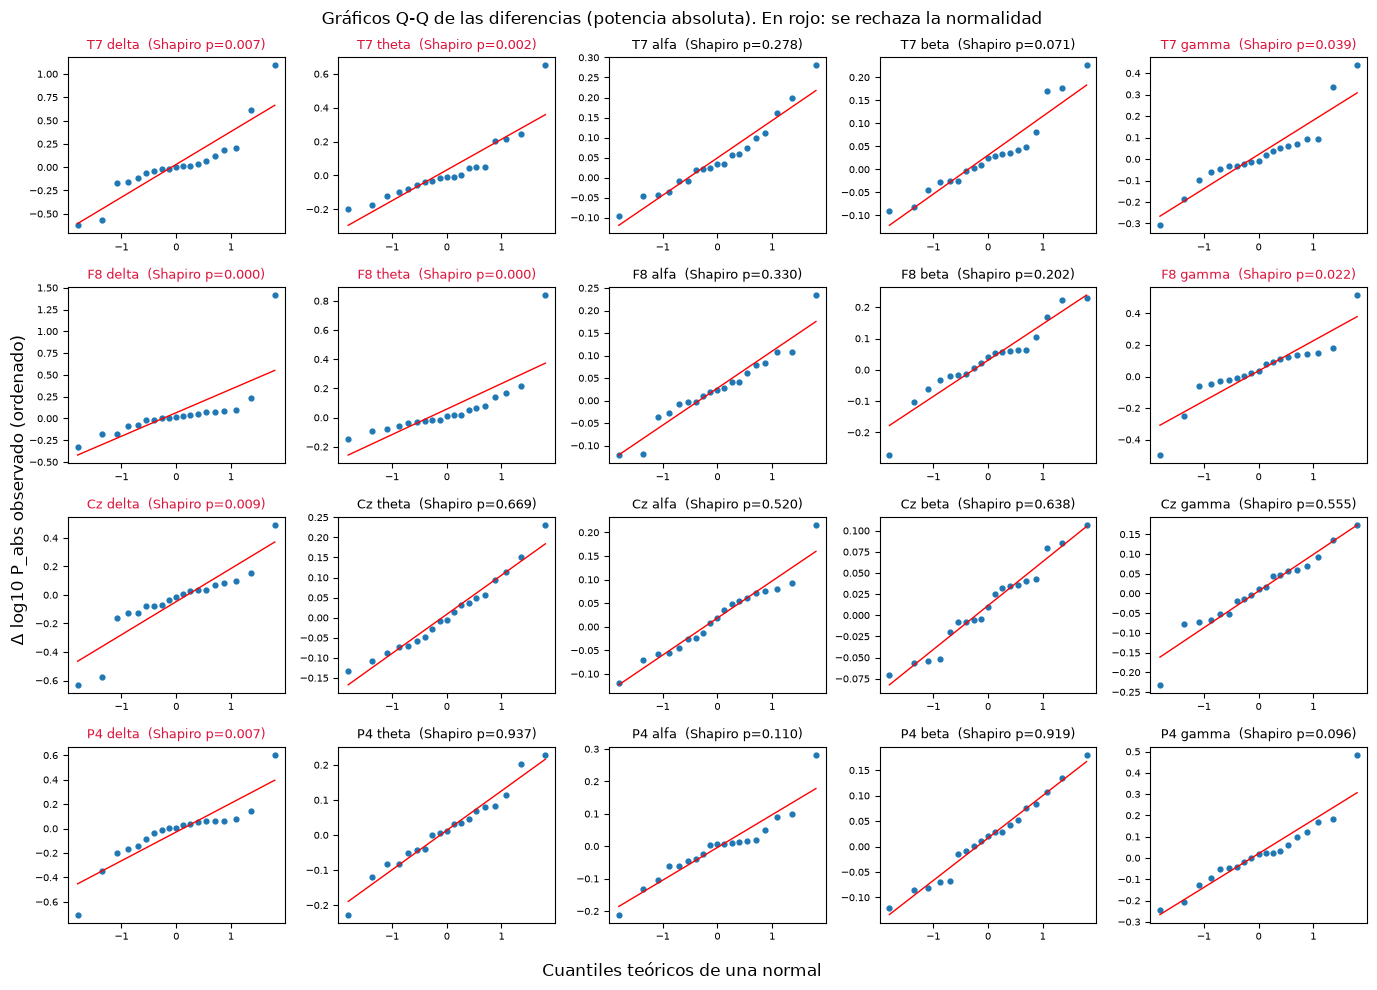

In [3]:
fig, axes = plt.subplots(4, 5, figsize=(14, 10))
for ax, (c, b) in zip(axes.flat, CELDAS):
    x = X['d_log_abs'][(c, b)].values
    (osm, osr), (m, q, _) = stats.probplot(x, dist='norm')
    ax.scatter(osm, osr, s=12)
    ax.plot(osm, m * osm + q, 'r-', lw=1)
    p = stats.shapiro(x).pvalue
    ax.set_title(f'{c} {b}  (Shapiro p={p:.3f})', fontsize=9, color='crimson' if p < .05 else 'k')
    ax.tick_params(labelsize=7)
fig.supxlabel('Cuantiles teóricos de una normal'); fig.supylabel('Δ log10 P_abs observado (ordenado)')
fig.suptitle('Gráficos Q-Q de las diferencias (potencia absoluta). En rojo: se rechaza la normalidad')
plt.tight_layout(); plt.show()

**Análisis** En casi la mitad de las celdas se rechaza la normalidad. Pasa sobre todo en **δ** y en **F8**, donde aparecen uno o dos sujetos muy alejados de la recta (los artefactos oculares vistos en el notebook 04). Por eso se usa **Wilcoxon como test principal**: un valor extremo solo cuenta como "el rango más alto" y no arrastra el resultado. El t pareado se muestra como complemento. Si los dos tests coinciden, el resultado es más confiable.

## 7.3 Test pareado nativo vs no nativo, por canal y banda

**Qué se hace.** En cada una de las 20 celdas, y para los dos descriptores (absoluta y relativa), se testea H₀: *"la mediana (Wilcoxon) o la media (t) de Δ es 0"*. Los tests son **bilaterales**: no suponemos de antemano si la nativa da más o menos potencia.

**Columnas de la tabla:**
- `media_delta`: diferencia promedio nativo − no nativo (en log10 para la absoluta, en puntos porcentuales para la relativa).
- `dz`, `dz_ic_inf`, `dz_ic_sup`: tamaño de efecto con su IC 95 % (notebook 04).
- `p_wilcoxon`, `p_t`: p-valores **sin corregir**.

In [4]:
filas = []
for v in VARS:
    for (c, b) in CELDAS:
        x = X[v][(c, b)].values
        filas.append({'descriptor': v, 'canal': c, 'banda': b,
                      'media_delta': x.mean(),
                      'p_wilcoxon': stats.wilcoxon(x).pvalue,
                      'p_t': stats.ttest_1samp(x, 0).pvalue})
tests = pd.DataFrame(filas).merge(
    efe[['descriptor', 'canal', 'banda', 'dz', 'dz_ic_inf', 'dz_ic_sup', 'pct_sujetos_pos']],
    on=['descriptor', 'canal', 'banda'])
print('Celdas con p < 0,05 SIN corregir:')
display(tests[(tests.p_wilcoxon < .05) | (tests.p_t < .05)].round(4))

Celdas con p < 0,05 SIN corregir:


,descriptor,canal,banda,media_delta,p_wilcoxon,p_t,dz,dz_ic_inf,dz_ic_sup,pct_sujetos_pos
2,d_log_abs,T7,alfa,0.049,0.0401,0.0317,0.5344,0.1463,0.9531,68.4211


**Cómo leerlo.** De 40 tests (20 por descriptor), **solo α en T7 (potencia absoluta)** da p < 0,05 sin corregir: Wilcoxon p ≈ 0,04, t p ≈ 0,03. Pero justamente esperábamos ~1 falso positivo cada 20 tests por azar, así que **un único p ≈ 0,04 entre 20 no alcanza para afirmar nada todavía**. Hay que corregir.

## 7.4 Corrección por comparaciones múltiples

Hay que corregir el p porque al tener 20 muestras (experimentos) es más fácil encontrar un positivo "de casualidad", es decir, mientras más muestras tengamos, más probabilidad hay de encontrar un resultado "significativo" por azar.

Se aplican tres correcciones, de la menos a la más estricta. Cada **familia** son los 20 tests de un descriptor.

**1. Benjamini-Hochberg (FDR, *False Discovery Rate*).** Controla la **proporción esperada de falsos positivos entre los resultados que declaramos significativos**. Por ejemplo, con FDR = 5 %, de cada 100 "descubrimientos" se esperan ~5 falsos. Cómo funciona: se ordenan los p de menor a mayor ($p_{(1)} \le \dots \le p_{(m)}$) y el de posición $k$ se compara con $\frac{k}{m}\cdot 0{,}05$. El p más chico tiene que superar el umbral más exigente (0,05/20 = 0,0025), el segundo 0,005, y así. Es la corrección estándar en EEG exploratorio porque no es tan conservadora.

**2. Holm.** Controla la probabilidad de **al menos un** falso positivo en toda la familia (FWER). Es una versión escalonada de Bonferroni (dividir 0,05 por la cantidad de tests), un poco menos severa. Es más estricta que FDR.

**3. Permutación con máximo estadístico (max-T).** Es la idea de los tests de permutación que usó Wagner et al. (2023):
- Si H₀ es cierta (no hay diferencia entre canciones), entonces **la etiqueta "nativo"/"no nativo" es intercambiable**, y el signo de cada $\Delta_i$ es como tirar una moneda.
- Se generan 20 000 "experimentos falsos" **cambiando al azar el signo** de los Δ de cada sujeto. En cada uno se calcula el estadístico t de las 20 celdas y se guarda **el máximo |t|**.
- El p corregido de una celda es la proporción de experimentos falsos donde el máximo |t| superó al |t| real.
- Así se responde: *"¿este efecto es más grande que el mayor efecto que el azar produce en cualquiera de las 20 celdas?"*. No supone normalidad y respeta la correlación entre canales y bandas.

In [5]:
def t_stat(M):
    n = M.shape[-2]
    return M.mean(-2) / (M.std(-2, ddof=1) / np.sqrt(n))

def maxT(M, n_perm=20000):
    M = np.asarray(M, float)                     # (n_sujetos, n_celdas)
    t_obs = t_stat(M)
    signos = rng.choice([-1.0, 1.0], size=(n_perm, M.shape[0], 1))
    t_perm = t_stat(signos * M[None])            # (n_perm, n_celdas)
    max_abs = np.abs(t_perm).max(1)
    p_corr = (max_abs[:, None] >= np.abs(t_obs)).mean(0)
    p_unc = (np.abs(t_perm) >= np.abs(t_obs)).mean(0)
    return p_unc, p_corr

def holm(p):
    # ordena los p, multiplica el k-ésimo por (m - k) y fuerza que no decrezcan
    p = np.asarray(p, float); m = len(p); orden = np.argsort(p)
    ajust = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[orden]))
    salida = np.empty(m); salida[orden] = ajust
    return salida

for v in VARS:
    m = tests.descriptor == v
    tests.loc[m, 'p_fdr'] = stats.false_discovery_control(tests.loc[m, 'p_wilcoxon'])
    tests.loc[m, 'p_holm'] = holm(tests.loc[m, 'p_wilcoxon'])
    p_unc, p_corr = maxT(X[v].values)
    tests.loc[m, 'p_perm'] = p_unc
    tests.loc[m, 'p_maxT'] = p_corr

tests['signif_fdr'] = tests.p_fdr < .05
tests.to_csv(os.path.join(RUTA, 'tests_paso7.csv'), index=False)
cols = ['descriptor', 'canal', 'banda', 'media_delta', 'dz', 'p_wilcoxon', 'p_t', 'p_perm', 'p_fdr', 'p_holm', 'p_maxT']
print('Celdas significativas tras FDR:', int(tests.signif_fdr.sum()), 'de', len(tests))
display(tests.sort_values('p_wilcoxon')[cols].head(8).round(4))

Celdas significativas tras FDR: 0 de 40


,descriptor,canal,banda,media_delta,dz,p_wilcoxon,p_t,p_perm,p_fdr,p_holm,p_maxT
2,d_log_abs,T7,alfa,0.0490,0.5344,0.0401,0.0317,0.0290,0.7275,0.8026,0.2660
7,d_log_abs,F8,alfa,0.0274,0.3396,0.1447,0.1560,0.1558,0.7275,1.0000,0.8542
9,d_log_abs,F8,gamma,0.0355,0.1802,0.1688,0.4425,0.4566,0.7275,1.0000,0.9998
8,d_log_abs,F8,beta,0.0305,0.2665,0.1688,0.2605,0.2638,0.7275,1.0000,0.9750
3,d_log_abs,T7,beta,0.0307,0.3654,0.1819,0.1286,0.1316,0.7275,1.0000,0.7812
30,d_rel_pp,Cz,delta,-3.1861,-0.2760,0.1956,0.2446,0.2560,0.9895,1.0000,0.9671
38,d_rel_pp,P4,beta,1.0161,0.2677,0.3124,0.2586,0.2584,0.9895,1.0000,0.9733
12,d_log_abs,Cz,alfa,0.0184,0.2408,0.3321,0.3078,0.3129,0.9600,1.0000,0.9906


**Cómo leerlo.** La tabla muestra las 8 celdas con p más chico.
- `p_perm` es el p de permutación sin corregir para cada celda (≈ igual al t: α en T7 sigue cerca de 0,03).
- Después de corregir, **ninguna celda es significativa**. Para α en T7: FDR ≈ 0,73, Holm ≈ 0,8 y max-T ≈ 0,27. Esto quiere decir que en ~1 de cada 4 experimentos falsos (signos al azar) aparece en *alguna* celda un efecto tan grande como el de α en T7.
- **Conclusión del 7.4:** con estos datos **no se puede afirmar** que la potencia en ninguna banda ni electrodo cambie entre la canción nativa y la no nativa.

### Gráfico de bosque (*forest plot*): efecto e incertidumbre de cada celda
- Cada fila es una combinación canal × banda.
- El **punto** es el $d_z$ (tamaño de efecto) y la **barra horizontal** es su IC 95 %.
- La **línea vertical en 0** es "sin efecto". Si la barra la cruza, con 95 % de confianza el efecto podría ser positivo, negativo o nulo.
- Hacia la derecha = más potencia con la canción **nativa**.
- Las líneas punteadas en ±0,2, ±0,5 y ±0,8 marcan efectos chico, mediano y grande.

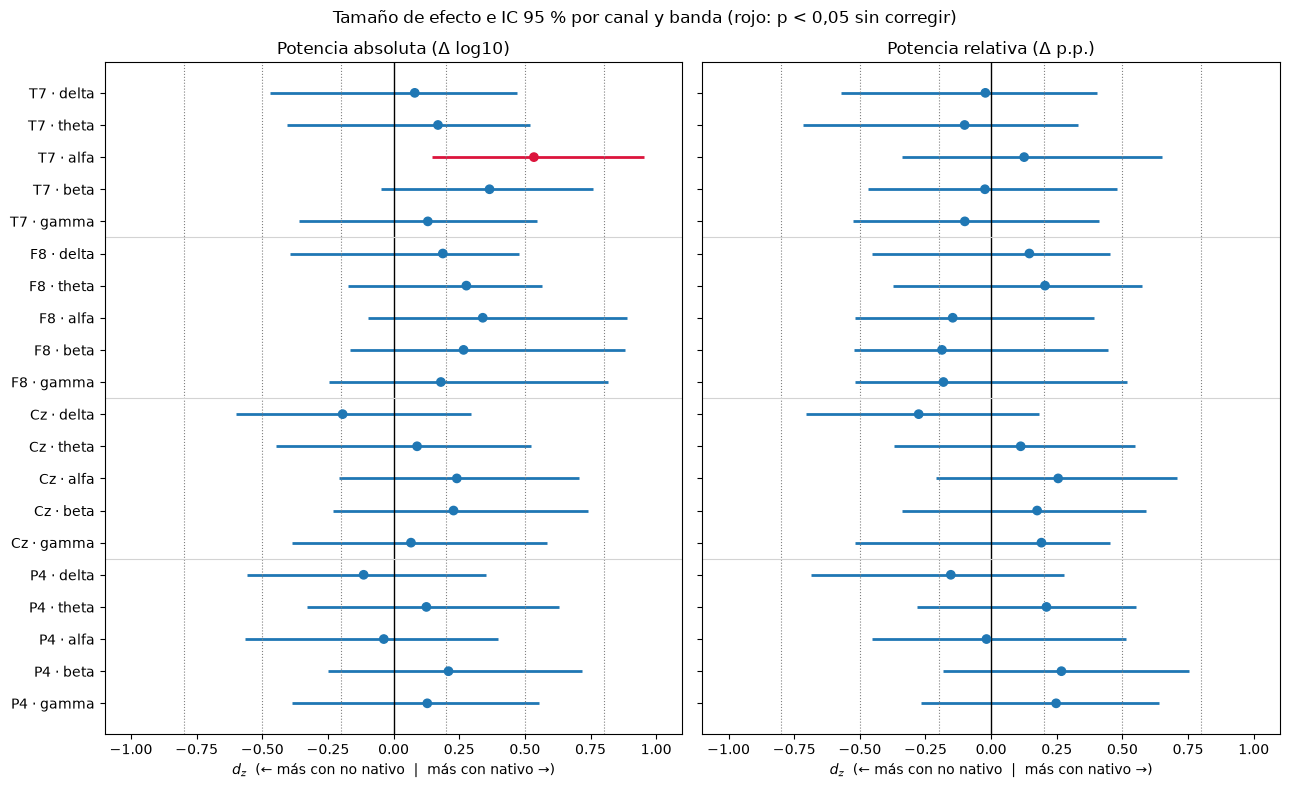

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
etiquetas = [f'{c} · {b}' for c, b in CELDAS]
for ax, v in zip(axes, VARS):
    t = tests[tests.descriptor == v].set_index(['canal', 'banda']).loc[CELDAS]
    y = np.arange(len(CELDAS))[::-1]
    col = np.where(t.p_wilcoxon < .05, 'crimson', 'tab:blue')
    ax.hlines(y, t.dz_ic_inf, t.dz_ic_sup, color=col, lw=2)
    ax.scatter(t.dz, y, color=col, zorder=3)
    ax.axvline(0, color='k', lw=1)
    for r in (0.2, 0.5, 0.8):
        ax.axvline(r, color='gray', ls=':', lw=0.8); ax.axvline(-r, color='gray', ls=':', lw=0.8)
    for k in range(1, len(CANALES)):
        ax.axhline(len(CELDAS) - 5 * k - 0.5, color='lightgray', lw=0.8)
    ax.set_yticks(y, etiquetas); ax.set_xlim(-1.1, 1.1)
    ax.set_xlabel('$d_z$  (← más con no nativo  |  más con nativo →)')
    ax.set_title(VARS[v])
fig.suptitle('Tamaño de efecto e IC 95 % por canal y banda (rojo: p < 0,05 sin corregir)')
plt.tight_layout(); plt.show()

**Cómo leerlo.**
- Casi todas las barras **cruzan el 0** y son **anchas** (van de ≈ −0,5 a ≈ +0,7). Con 19 sujetos la estimación es muy imprecisa, y los datos son compatibles tanto con "no hay efecto" como con efectos moderados en cualquier dirección.
- En **absoluta**, la mayoría de los puntos están levemente a la derecha (más potencia con la nativa en casi todo). En **relativa** quedan repartidos a ambos lados. Esto se analiza en 7.5.
- α en T7 (absoluta) es la única barra que queda apenas a la derecha del 0, pero ese IC no está corregido por múltiples comparaciones.

## 7.5 ¿Cambio específico de una banda o cambio "global" de potencia?

**Por qué importa.** Si en una condición **toda** la señal de un electrodo sube (porque cambió el contacto del electrodo, la pasta se secó o el sujeto se movió más), todas las bandas suben juntas en potencia **absoluta**, pero la **relativa** no cambia. Eso no sería un efecto del idioma sobre un ritmo cerebral concreto. Para distinguirlo, se compara el Δ de la **potencia total** (0,5–40 Hz) con el Δ de cada banda.

In [8]:
tot = pot[pot.banda == 'delta'].pivot_table(index=['sujeto', 'canal'], columns='condicion', values='p_total')
d_tot = (np.log10(tot.nativo) - np.log10(tot.no_nativo)).rename('d_log_total').reset_index()
res = d_tot.groupby('canal')['d_log_total'].agg(
    media='mean', desvio='std', dz=lambda x: x.mean() / x.std(),
    p_wilcoxon=lambda x: stats.wilcoxon(x).pvalue).reindex(CANALES)
res['cambio_pct'] = (10 ** res.media - 1) * 100
print('Δ de la potencia TOTAL (nativo − no nativo):')
display(res.round(3))
t7a = X['d_log_abs'][('T7', 'alfa')]
print(f"T7 α: media Δ = {t7a.mean():.3f} (≈ {(10**t7a.mean()-1)*100:.0f} %), desvío = {t7a.std():.3f}")

Δ de la potencia TOTAL (nativo − no nativo):


,media,desvio,dz,p_wilcoxon,cambio_pct
canal,,,,,
T7,0.050,0.220,0.227,0.312,12.196
F8,0.053,0.249,0.213,0.490,12.971
Cz,-0.004,0.112,-0.033,0.953,-0.843
P4,-0.005,0.105,-0.048,0.651,-1.168


T7 α: media Δ = 0.049 (≈ 12 %), desvío = 0.092


**Cómo leerlo.**
- La potencia total no cambia de forma significativa en ningún canal.
- En **T7** la potencia total sube en promedio **lo mismo** que α (~+12 %), pero con un desvío mucho mayor (por el ruido en δ). Es decir, α en T7 no sube *más* que el resto de la señal: se mueve igual que todo T7, solo que α es más estable entre sujetos y por eso su $d_z$ sale más alto. Coincide con que la **α relativa en T7 casi no cambia** ($d_z$ ≈ 0,13).
- **Interpretación:** lo de T7 se parece más a un **cambio general de amplitud en ese electrodo** entre los dos registros que a un efecto específico del idioma sobre el ritmo α.

## 7.6 ¿Los electrodos difieren entre sí? ¿El efecto de la canción depende del electrodo?

En el anteproyecto planteamos dos cosas distintas:

**(a) Diferencias entre electrodos dentro de cada condición** (la "topografía"). ¿La potencia relativa de cada banda es distinta en T7, F8, Cz y P4?

**(b) Si la diferencia entre condiciones cambia según el electrodo** (la **interacción** condición × electrodo). ¿El Δ de T7 es distinto del Δ de P4, por ejemplo?

**Test de Friedman.** Es la versión no paramétrica del ANOVA de medidas repetidas. Sirve cuando **los mismos sujetos** se miden en **más de dos** situaciones (acá, 4 electrodos). Dentro de cada sujeto, ordena los 4 valores del 1 al 4 y mira si algún electrodo tiende a quedar sistemáticamente arriba o abajo. H₀: *los 4 electrodos son intercambiables*.
- Para (a) se aplica a la potencia relativa de cada banda y condición.
- Para (b) se aplica a los **Δ** de cada banda: si los Δ de los 4 electrodos son intercambiables, el efecto de la canción no depende del electrodo.

In [9]:
filas = []
for cond in ['nativo', 'no_nativo']:
    for b in BANDAS:
        M = pot[(pot.banda == b) & (pot.condicion == cond)].pivot(index='sujeto', columns='canal', values='p_rel')[CANALES]
        filas.append({'condicion': cond, 'banda': b,
                      'p_friedman': stats.friedmanchisquare(*M.T.values).pvalue,
                      **{f'mediana_{c} (%)': 100 * M[c].median() for c in CANALES}})
topo = pd.DataFrame(filas)
topo['p_fdr'] = stats.false_discovery_control(topo.p_friedman)
print('(a) Diferencias entre electrodos (potencia relativa):')
display(topo.round(4))

filas = []
for v in VARS:
    for b in BANDAS:
        M = X[v].xs(b, axis=1, level='banda')[CANALES]
        filas.append({'descriptor': v, 'banda': b, 'p_friedman': stats.friedmanchisquare(*M.T.values).pvalue})
inter = pd.DataFrame(filas)
inter['p_fdr'] = inter.groupby('descriptor')['p_friedman'].transform(stats.false_discovery_control)
print('(b) ¿El Δ (nativo − no nativo) depende del electrodo?  (interacción)')
display(inter.round(3))

(a) Diferencias entre electrodos (potencia relativa):


,condicion,banda,p_friedman,mediana_T7 (%),mediana_F8 (%),mediana_Cz (%),mediana_P4 (%),p_fdr
0,nativo,delta,0.0000,29.4296,40.2692,27.9109,18.2643,0.0000
1,nativo,theta,0.0000,9.8414,8.6800,11.7036,7.9651,0.0001
2,nativo,alfa,0.0000,32.7731,21.9242,38.8815,56.7258,0.0000
3,nativo,beta,0.0155,20.4078,15.7326,16.3868,15.5606,0.0155
4,nativo,gamma,0.0130,4.1021,3.5352,2.6050,2.4659,0.0145
5,no_nativo,delta,0.0000,28.9188,37.7949,30.2693,19.9756,0.0000
6,no_nativo,theta,0.0000,10.6625,9.4492,12.4643,7.7166,0.0000
7,no_nativo,alfa,0.0000,35.8565,25.5543,39.0326,53.9415,0.0000
8,no_nativo,beta,0.0004,20.7930,15.8821,15.8584,14.9650,0.0006
9,no_nativo,gamma,0.0006,3.6112,3.0095,2.6428,2.6972,0.0007


(b) ¿El Δ (nativo − no nativo) depende del electrodo?  (interacción)


,descriptor,banda,p_friedman,p_fdr
0,d_log_abs,delta,0.882,0.882
1,d_log_abs,theta,0.671,0.882
2,d_log_abs,alfa,0.247,0.668
3,d_log_abs,beta,0.715,0.882
4,d_log_abs,gamma,0.267,0.668
5,d_rel_pp,delta,0.157,0.262
6,d_rel_pp,theta,0.086,0.215
7,d_rel_pp,alfa,0.067,0.215
8,d_rel_pp,beta,0.422,0.527
9,d_rel_pp,gamma,0.730,0.730


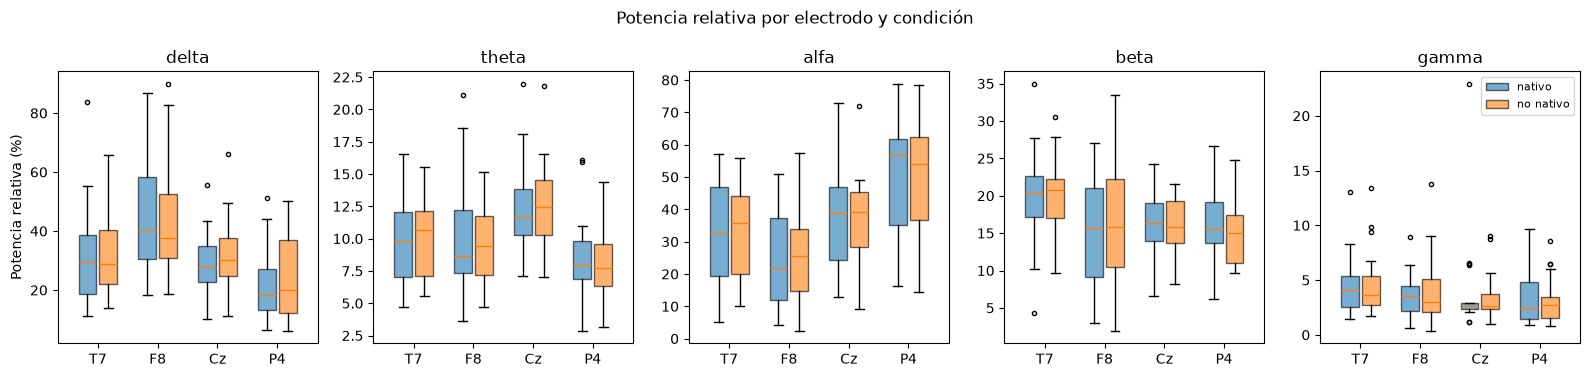

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, b in zip(axes, BANDAS):
    datos, pos, cols = [], [], []
    for k, c in enumerate(CANALES):
        for j, cond in enumerate(['nativo', 'no_nativo']):
            datos.append(100 * pot[(pot.banda == b) & (pot.canal == c) & (pot.condicion == cond)].p_rel.values)
            pos.append(k + (j - 0.5) * 0.35); cols.append('tab:blue' if cond == 'nativo' else 'tab:orange')
    bp = ax.boxplot(datos, positions=pos, widths=0.3, patch_artist=True, showfliers=True,
                    flierprops=dict(markersize=3))
    for patch, col in zip(bp['boxes'], cols):
        patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.set_xticks(range(4), CANALES); ax.set_title(b)
axes[0].set_ylabel('Potencia relativa (%)')
axes[-1].legend([bp['boxes'][0], bp['boxes'][1]], ['nativo', 'no nativo'], fontsize=8)
fig.suptitle('Potencia relativa por electrodo y condición')
plt.tight_layout(); plt.show()

**Cómo leer el gráfico de cajas.** Cada caja resume 19 sujetos: la línea del medio es la **mediana**, la caja va del percentil 25 al 75 (el 50 % central de los sujetos), los "bigotes" llegan a los valores típicos y los puntos sueltos son **valores atípicos**.

**Resultados.**
- **(a) Los electrodos difieren mucho entre sí** (Friedman p < 0,001 en δ, θ y α en ambas condiciones; también en β y γ). Es lo esperado fisiológicamente: **α domina en P4** (parietal, ~55 %), **δ es máxima en F8** (frontal, cerca del ojo, ~40 %) y **θ es máxima en Cz** (fronto-central). Esto confirma que los registros tienen sentido y que la topografía es la conocida.
- **(b) No hay interacción.** Ningún Friedman sobre los Δ da significativo. En potencia absoluta todos dan p > 0,2. En relativa los más bajos son α y θ (p ≈ 0,07–0,09), que no llegan a 0,05 ni sobreviven FDR (q ≈ 0,2). **No hay evidencia de que la canción nativa afecte de forma distinta a distintos electrodos.**
- En el gráfico se ve: dentro de cada electrodo, las cajas azul y naranja casi se superponen. Las diferencias **entre electrodos** son mucho más grandes que las diferencias **entre condiciones**.

## 7.7 Robustez del único resultado nominal (α en T7)

Un resultado es **robusto** si no depende de uno o dos sujetos en particular. Se hacen dos chequeos:
1. **Sacar los sujetos con artefactos** detectados en el notebook 04 (s01, s02, s05, s16).
2. **Leave-one-out (dejar uno afuera):** se repite el Wilcoxon 19 veces, sacando cada vez a un sujeto distinto. Si el p salta por encima de 0,05 al sacar a una sola persona, el resultado depende de ella.

Sin sujetos con artefactos (n=15): d_z = 0.45, Wilcoxon p = 0.151


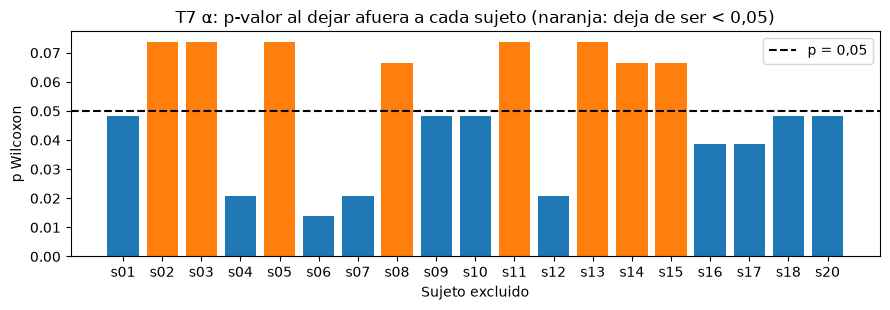

Al sacar 1 sujeto, p > 0,05 en 8 de 19 casos


In [12]:
x = t7a.copy()
sin_art = x.drop(['s01', 's02', 's05', 's16'])
print(f'Sin sujetos con artefactos (n={len(sin_art)}): d_z = {sin_art.mean()/sin_art.std():.2f}, '
      f'Wilcoxon p = {stats.wilcoxon(sin_art).pvalue:.3f}')
loo = pd.Series({s: stats.wilcoxon(x.drop(s)).pvalue for s in x.index})
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(loo.index, loo.values, color=np.where(loo > .05, 'tab:orange', 'tab:blue'))
ax.axhline(0.05, color='k', ls='--', label='p = 0,05')
ax.set_ylabel('p Wilcoxon'); ax.set_xlabel('Sujeto excluido')
ax.set_title('T7 α: p-valor al dejar afuera a cada sujeto (naranja: deja de ser < 0,05)')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Al sacar 1 sujeto, p > 0,05 en {int((loo > .05).sum())} de {len(loo)} casos')

**Cómo leerlo.** Sin los 4 sujetos con artefactos, el efecto baja ($d_z$ ≈ 0,45) y deja de ser significativo (p ≈ 0,15). En el leave-one-out, **sacar a un solo sujeto alcanza para que p supere 0,05 en casi la mitad de los casos**. Es un resultado **frágil**: está en el límite y depende de quiénes estén en la muestra.

## 7.9 Conclusión del paso 7

1. **No hay diferencias estadísticamente significativas** en potencia absoluta ni relativa entre la canción nativa y la no nativa, en ningún electrodo ni banda, después de corregir por comparaciones múltiples (FDR, Holm y permutación max-T).
2. El único efecto nominal (α absoluta en T7, $d_z$ ≈ 0,53, p ≈ 0,04 sin corregir) **no sobrevive a la corrección**, es **frágil** (leave-one-out, exclusión de artefactos) y se explica en buena parte por un **cambio general de amplitud en T7**, no por un cambio específico de α.
3. Los **electrodos difieren mucho entre sí** (topografía esperable: α parietal, δ frontal, θ central), pero **no hay evidencia de que el efecto de la canción dependa del electrodo** (sin interacción).
4. El estudio tenía **potencia baja**: con n = 19 solo se podían detectar efectos grandes ($d_z$ ≥ 0,7–1,0). Los resultados son **compatibles con efectos chicos o moderados** que esta muestra no puede detectar.

# Paso 8 — Análisis exploratorio y limitaciones

En el paso 7 se testearon las hipótesis planteadas de antemano. En el paso 8 se buscan **patrones que puedan generar hipótesis nuevas**, usando información extra (los metadatos de los sujetos). Como los grupos son muy chicos y hacemos varias preguntas, **estos resultados no prueban nada**. Sirven para *sugerir* qué valdría la pena estudiar con más sujetos. Hay que reportarlos así.

La pregunta del anteproyecto es si **la familiaridad con el idioma** se relaciona con las diferencias. Se aborda de tres maneras:
1. **Familiaridad directa:** dos sujetos (s11, s17) declaran hablar fluido italiano, que es justamente el idioma de su canción "no nativa". Para ellos, las dos canciones son comprensibles.
2. **Familiaridad asimétrica entre grupos:** los italianos escuchan árabe como no nativo, mientras que el resto escucha italiano.
3. **Diseño cruzado italianos vs árabes**, para separar el efecto del *idioma* del de *la canción*.

## 8.1 Familiaridad directa: ¿los sujetos que entienden ambas canciones cambian menos?

**Hipótesis.** Si la diferencia nativo/no nativo se debe a **comprender la letra**, en s11 y s17 debería ser **más chica**, porque entienden las dos canciones.

**Medida.** Para cada sujeto, el **promedio de |Δ|** (valor absoluto de la diferencia en log de la potencia absoluta) sobre las 20 celdas. Mide "cuánto cambió el EEG en general entre las dos canciones", sin importar la dirección.

**Test exacto por permutación.** Con solo 2 sujetos no se puede usar un test clásico, pero se puede hacer una cuenta exacta:
- Hay $\binom{19}{2} = 171$ maneras de elegir 2 sujetos de 19.
- Para cada par se calcula el |Δ| medio.
- **p = proporción de pares con |Δ| medio tan chico o más que el de s11 + s17.**
- Si los dos sujetos fluidos fueran "dos cualesquiera" (H₀), su valor caería en cualquier lugar de esa distribución.

|Δ| medio de s11 y s17: 0.035  |  resto de los sujetos: 0.107
Posiciones en el ranking (1 = el que menos cambia): s11: 4°, s17: 1°
p exacto = 3/171 = 0.018


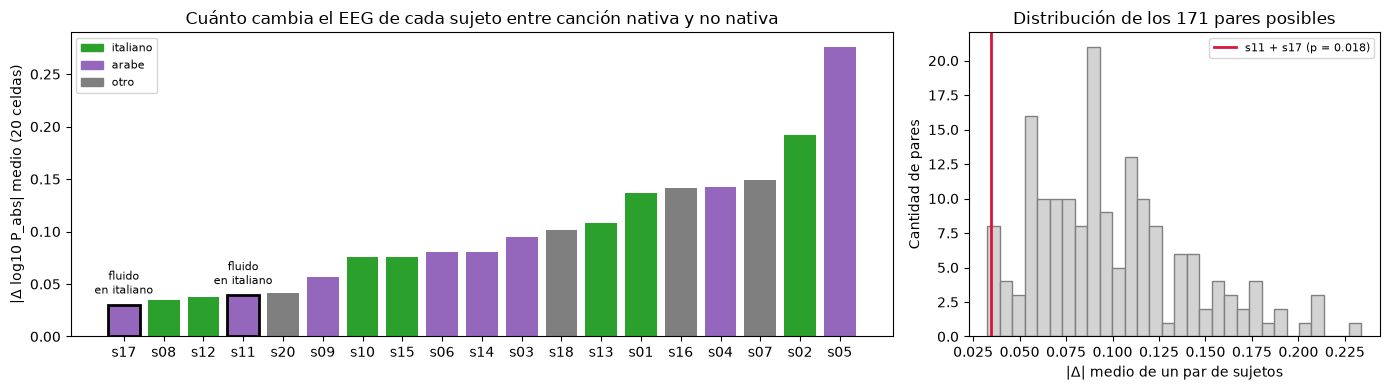

In [13]:
abs_suj = X['d_log_abs'].abs().mean(axis=1).sort_values()
obs = abs_suj[FLUIDOS].mean()
pares = np.array([abs_suj[list(par)].mean() for par in itertools.combinations(abs_suj.index, 2)])
p_exacto = (pares <= obs).mean()
print(f'|Δ| medio de s11 y s17: {obs:.3f}  |  resto de los sujetos: {abs_suj.drop(FLUIDOS).mean():.3f}')
print(f'Posiciones en el ranking (1 = el que menos cambia): ' +
      ', '.join(f'{s}: {abs_suj.index.get_loc(s) + 1}°' for s in FLUIDOS))
print(f'p exacto = {int((pares <= obs).sum())}/{len(pares)} = {p_exacto:.3f}')

col_g = {'italiano': 'tab:green', 'arabe': 'tab:purple', 'otro': 'tab:gray'}
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
ax.bar(abs_suj.index, abs_suj.values, color=meta.loc[abs_suj.index, 'grupo'].map(col_g),
       edgecolor=['k' if s in FLUIDOS else 'none' for s in abs_suj.index], linewidth=2)
for s in FLUIDOS:
    ax.annotate('fluido\nen italiano', (abs_suj.index.get_loc(s), abs_suj[s]), ha='center',
                xytext=(0, 8), textcoords='offset points', fontsize=8)
ax.set_ylabel('|Δ log10 P_abs| medio (20 celdas)')
ax.set_title('Cuánto cambia el EEG de cada sujeto entre canción nativa y no nativa')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in col_g.items()], fontsize=8)
ax = axes[1]
ax.hist(pares, bins=30, color='lightgray', edgecolor='gray')
ax.axvline(obs, color='crimson', lw=2, label=f's11 + s17 (p = {p_exacto:.3f})')
ax.set_xlabel('|Δ| medio de un par de sujetos'); ax.set_ylabel('Cantidad de pares')
ax.set_title('Distribución de los 171 pares posibles'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cómo leer el gráfico.**
- **Izquierda:** cada barra es un sujeto, ordenado de menor a mayor cambio. Los dos sujetos fluidos en italiano (borde negro) están entre los **4 que menos cambian** (s17 1°, s11 4°).
- **Derecha:** la distribución gris muestra qué |Δ| medio tienen todos los pares posibles de sujetos. La línea roja es el par s11 + s17. Solo **3 de 171 pares** (p ≈ 0,018) cambian tan poco o menos.

**Interpretación.** El resultado **va en la dirección que predice la hipótesis de comprensión**: los sujetos que entienden las dos canciones muestran menos diferencia entre ellas. Pero tiene **tres cuidados importantes**:
1. Son **solo 2 sujetos**: no alcanza para concluir.
2. Un |Δ| chico también puede reflejar **registros más estables o con menos ruido**, sin relación con el idioma (s08 y s12, italianos que *no* entienden árabe, cambian casi igual de poco).
3. Es **una de varias preguntas exploratorias**: si se corrigiera por todas las que se hacen en este paso, el p subiría.

In [14]:
x = X['d_log_abs'][('T7', 'alfa')]
print('T7 α — Δ de los sujetos fluidos y su percentil dentro del grupo:')
for s in FLUIDOS:
    print(f'  {s}: Δ = {x[s]:+.3f}  (percentil {stats.percentileofscore(x, x[s]):.0f})')

T7 α — Δ de los sujetos fluidos y su percentil dentro del grupo:
  s11: Δ = +0.110  (percentil 84)
  s17: Δ = -0.009  (percentil 32)


En el único efecto nominal del paso 7 (α en T7), **los fluidos no se comportan igual**: s17 está cerca de 0 (como predice la hipótesis), pero s11 tiene uno de los Δ más grandes (percentil 84). Esto refuerza que el resultado de α en T7 no se explica claramente por comprensión.

## 8.2 Familiaridad asimétrica: italianos vs el resto

**Idea.** El dataset se registró en la Universidad Politécnica de las Marcas (Ancona, **Italia**). Es razonable suponer (**supuesto, no está en los metadatos**) que los sujetos no italianos viven o estudian en Italia y tienen **algo de exposición al italiano**, que es su canción "no nativa". En cambio, para los italianos la canción no nativa es en **árabe**, un idioma que muy probablemente no conocen.

**Predicción.** Si la familiaridad importa, la diferencia nativo/no nativo debería ser **más marcada en los italianos** (contraste "entiendo todo vs no entiendo nada") que en el resto (contraste "lengua materna vs idioma que escucho a diario").

**Test de Mann-Whitney U.** Compara **dos grupos distintos de personas** (no pareados). Es la versión no paramétrica del t de Student para muestras independientes. Junta todos los Δ, los ordena y mira si los de un grupo tienden a ocupar los puestos más altos. H₀: *los dos grupos tienen la misma distribución de Δ*.

In [15]:
filas = []
for v in VARS:
    for (c, b) in CELDAS:
        s = X[v][(c, b)]
        it = s[meta.grupo == 'italiano']; resto = s[meta.grupo != 'italiano']; ar = s[meta.grupo == 'arabe']
        filas.append({'descriptor': v, 'canal': c, 'banda': b,
                      'media_italianos': it.mean(), 'media_resto': resto.mean(), 'media_arabes': ar.mean(),
                      'p_it_vs_resto': stats.mannwhitneyu(it, resto).pvalue,
                      'p_it_vs_arabes': stats.mannwhitneyu(it, ar).pvalue})
grupos = pd.DataFrame(filas)
for col in ['p_it_vs_resto', 'p_it_vs_arabes']:
    grupos[col.replace('p_', 'fdr_')] = grupos.groupby('descriptor')[col].transform(stats.false_discovery_control)
grupos.to_csv(os.path.join(RUTA, 'paso8_grupos.csv'), index=False)
print(f"Grupos: {(meta.grupo=='italiano').sum()} italianos, {(meta.grupo!='italiano').sum()} resto "
      f"({(meta.grupo=='arabe').sum()} árabes + {(meta.grupo=='otro').sum()} otros)")
display(grupos.sort_values('p_it_vs_resto').head(6).round(3))

Grupos: 7 italianos, 12 resto (8 árabes + 4 otros)


,descriptor,canal,banda,media_italianos,media_resto,media_arabes,p_it_vs_resto,p_it_vs_arabes,fdr_it_vs_resto,fdr_it_vs_arabes
17,d_log_abs,P4,alfa,0.074,-0.049,-0.041,0.005,0.040,0.105,0.401
36,d_rel_pp,P4,theta,-0.700,1.174,1.052,0.045,0.281,0.556,0.959
38,d_rel_pp,P4,beta,-1.373,2.410,1.873,0.056,0.054,0.556,0.959
13,d_log_abs,Cz,beta,0.041,-0.006,-0.017,0.068,0.040,0.435,0.401
16,d_log_abs,P4,theta,0.042,-0.003,0.004,0.120,0.232,0.435,0.580
7,d_log_abs,F8,alfa,0.055,0.012,0.007,0.120,0.152,0.435,0.580


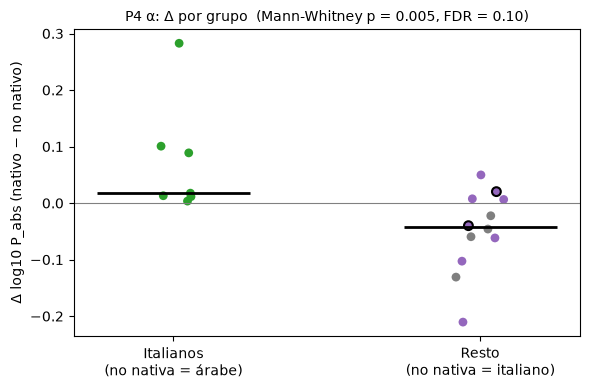

In [16]:
x = X['d_log_abs'][('P4', 'alfa')]
fig, ax = plt.subplots(figsize=(6, 4))
for k, (g, lab) in enumerate([('italiano', 'Italianos\n(no nativa = árabe)'), ('resto', 'Resto\n(no nativa = italiano)')]):
    sel = (meta.grupo == 'italiano') if g == 'italiano' else (meta.grupo != 'italiano')
    y = x[sel]
    ax.scatter(k + rng.uniform(-0.08, 0.08, len(y)), y, c=meta.loc[y.index, 'grupo'].map(col_g), s=40,
               edgecolor=['k' if s in FLUIDOS else 'none' for s in y.index], linewidth=1.5)
    ax.hlines(y.median(), k - 0.25, k + 0.25, color='k', lw=2)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks([0, 1], ['Italianos\n(no nativa = árabe)', 'Resto\n(no nativa = italiano)'])
p = grupos.query("descriptor=='d_log_abs' and canal=='P4' and banda=='alfa'")
ax.set_title(f"P4 α: Δ por grupo  (Mann-Whitney p = {p.p_it_vs_resto.item():.3f}, FDR = {p.fdr_it_vs_resto.item():.2f})", fontsize=10)
ax.set_ylabel('Δ log10 P_abs (nativo − no nativo)')
plt.tight_layout(); plt.show()

**Cómo leerlo.**
- Cada punto es un sujeto y la línea negra es la mediana del grupo. Los puntos con borde negro son s11 y s17.
- La celda con la diferencia más marcada entre grupos es **α en P4** (parietal). **Los 7 italianos** tienen Δ > 0 (más α con la canción nativa), aunque en 4 de ellos es casi 0. En el resto solo 4 de 12 son positivos, y el Δ medio es negativo. Sin corregir, p ≈ 0,005.
- **Después de FDR sobre las 20 celdas, q ≈ 0,1: no es significativo.**
- **Interpretación (exploratoria):** el patrón es compatible con la idea de que el contraste "nativo vs idioma totalmente desconocido" (italianos) produce un cambio en α parietal que el contraste "nativo vs idioma conocido" (resto) no produce. Pero hay explicaciones alternativas igual de válidas. Para los italianos, la canción no nativa es **siempre la misma canción árabe**, y para el resto es **siempre la misma canción italiana**, así que la diferencia puede deberse a **las canciones** y no a la familiaridad. Eso se analiza en 8.3.

## 8.4 Relación con la bibliografía

¿Qué dice la literatura sobre α y comprensión del lenguaje, y cómo se compara con lo que encontramos?

- **Obleser & Weisz (2012, *Cerebral Cortex*)** y **Becker et al. (2013, *Frontiers in Systems Neuroscience*)** estudiaron palabras habladas degradadas con distinto grado de inteligibilidad. Encontraron que **cuanto más inteligible es el habla, mayor es la supresión de α** (baja la potencia α), y en Becker et al. el efecto se ubicó sobre la **corteza temporal izquierda**. La interpretación es que la región se "activa" para procesar el lenguaje comprensible.
- **Zioga et al. (2023, *Journal of Neuroscience*)** mostraron con escucha de cuentos naturales (idioma nativo vs uno que no entendían) que la potencia α en **regiones temporales izquierdas** sigue la estructura lingüística del habla comprendida.
- **Grant et al. (2022, *Frontiers in Psychology*)** encontraron **más α al escuchar en el segundo idioma (L2)** que en el nativo, sobre todo con ruido. Lo interpretan como mayor **demanda de atención** al procesar un idioma menos dominado.
- **Wagner et al. (2023, *Neuropsychologia*)**, citado en el anteproyecto, encontró diferencias en α y β entre patrones fonológicos nativos y no nativos.

**Comparación con nuestros datos.**
- Según la literatura, el sitio más probable para un efecto era justamente **T7 (temporal izquierdo)**, y ahí apareció nuestro único resultado nominal. Pero **en la dirección opuesta** a lo esperado: tanto la "supresión de α por comprensión" (Becker, Obleser) como la "más α por esfuerzo en L2" (Grant) predicen **menos α con la canción nativa**, y nosotros vimos **más**.
- Posibles razones de la discrepancia:
  1. Esos estudios miden **cambios relacionados a eventos** (α en los ~0,5–1 s después de cada palabra, comparado con una línea de base). Nosotros medimos **potencia promedio durante 2 minutos**, que mezcla muchos procesos.
  2. Son estímulos de **habla**, no **canciones**, donde la música (melodía, ritmo) tiene mucho peso.
  3. Nuestro efecto **no sobrevive a la corrección** y se comporta como un **cambio general de amplitud en T7** (7.5). Lo más probable es que sea un falso positivo o un efecto del orden de registro.
- El resultado de **familiaridad** (8.1: los que entienden las dos canciones cambian menos) sí es **coherente con la idea general** de esta literatura: lo que importa es **comprender** el lenguaje y no solo que esté presente.

## 8.5 Limitaciones del estudio

| Limitación | Por qué afecta | Qué tan grave es acá |
|---|---|---|
| **Pocos sujetos (n = 19)** | Solo se detectan efectos grandes ($d_z$ ≥ 0,7–1,0); los subgrupos (7, 8, 4, 2 sujetos) tienen todavía menos potencia | **Alta**: es la razón principal de no encontrar efectos (7.7) |
| **Orden fijo (nativa siempre antes)** | Fatiga, somnolencia, adaptación o cambios en el contacto de los electrodos se confunden con la condición. El diseño cruzado no lo corrige (8.3) | **Alta**: la leve tendencia a más potencia en la nativa podría ser solo el orden |
| **Canciones distintas (diferencias acústicas)** | Tempo, volumen, voz e instrumentación difieren entre canciones. Para el grupo "otro", la canción nativa es distinta en cada sujeto (letón, inglés, urdu) | **Media**: el diseño cruzado italianos/árabes lo controla en parte |
| **Solo 4 electrodos** | No se puede estudiar la distribución espacial con detalle ni localizar fuentes; un artefacto en un electrodo pesa mucho | **Media** |
| **Artefactos oculares/musculares** | F8 (cerca del ojo) tiene δ muy alta en varios sujetos (s01: ~100 veces el resto). No se aplicó ICA ni rechazo de segmentos. T7 y F8 pueden tener EMG en γ | **Media**: los Δ en log son robustos, pero la potencia relativa en F8 queda contaminada |
| **Sin línea de base** | No se normalizó respecto del reposo (ex01/ex02), así que no se puede distinguir "la música cambia el EEG" de "una canción lo cambia más que otra" | **Media** |
| **Familiaridad poco medida** | Solo hay un comentario libre ("Fluent in Italian") en 3 sujetos (uno, s19, excluido). No hay nivel de idioma, conocimiento previo de la canción ni preferencia musical | **Alta** para el paso 8 |
| **Medida promedio de 2 min** | La potencia de toda la canción no capta respuestas rápidas ligadas a cada palabra (que es donde la literatura encuentra efectos) | **Media** |
| **Registros de distinta duración** | s05_ex05 dura ~200 s y el resto 120 s. La PSD es una densidad y no se sesga, pero su estimación es más precisa | **Baja** |
| **Múltiples comparaciones exploratorias** | En el paso 8 se hacen varias preguntas, así que algún p < 0,05 es esperable por azar | **Media**: por eso se reportan como hipótesis |

## 8.6 Conclusiones generales (pasos 7 y 8)

1. **Paso 7:** no se encontraron diferencias significativas en la potencia espectral (absoluta ni relativa) entre la escucha de canciones en idioma nativo y no nativo, en ninguno de los cuatro electrodos ni de las cinco bandas, después de corregir por comparaciones múltiples. Los tamaños de efecto fueron chicos y los intervalos amplios. La topografía (α parietal, δ frontal, θ central) es la esperada y no cambia con la condición.
2. **Paso 8 (exploratorio):**
   - Los dos sujetos que entienden ambas canciones (fluidos en italiano) están entre los que **menos cambian** su EEG entre condiciones (p exacto ≈ 0,02). Es coherente con la idea de que la **comprensión** es lo que diferencia las condiciones, pero son solo 2 sujetos.
   - Los italianos (contraste con un idioma desconocido) muestran una tendencia a **más α parietal** con la canción nativa, que el resto no muestra. No sobrevive a la corrección y podría deberse a la canción.
   - El diseño cruzado no muestra efectos claros de la canción. La leve tendencia general a más potencia en la canción nativa **no se puede separar del orden de presentación**.
3. **Para un estudio futuro:** más sujetos, orden contrabalanceado (mitad escucha primero la no nativa), las mismas canciones para todos, medición del nivel de idioma, y análisis relacionado a eventos (por palabra) en lugar de potencia promedio.

### Referencias
- Becker, R., Pefkou, M., Michel, C. M., & Hervais-Adelman, A. G. (2013). Left temporal alpha-band activity reflects single word intelligibility. *Frontiers in Systems Neuroscience, 7*, 121. https://doi.org/10.3389/fnsys.2013.00121
- Grant, A. M., Kousaie, S., Coulter, K., Gilbert, A. C., Baum, S. R., Gracco, V., Titone, D., Klein, D., & Phillips, N. A. (2022). Age of acquisition modulates alpha power during bilingual speech comprehension in noise. *Frontiers in Psychology, 13*, 865857. https://doi.org/10.3389/fpsyg.2022.865857
- Obleser, J., & Weisz, N. (2012). Suppressed alpha oscillations predict intelligibility of speech and its acoustic details. *Cerebral Cortex, 22*(11), 2466–2477.
- Wagner, M., Rusiniak, M., Higby, E., & Nourski, K. V. (2023). Sensory processing of native and non-native phonotactic patterns in the alpha and beta frequency bands. *Neuropsychologia, 189*, 108659.
- Zioga, I., Weissbart, H., Lewis, A. G., Haegens, S., & Martin, A. E. (2023). Naturalistic spoken language comprehension is supported by alpha and beta oscillations. *Journal of Neuroscience, 43*(20), 3718–3732.